In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from collections import deque
import random
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import time
import numpy as np
from scipy.signal import welch
import pywt
import matplotlib.pyplot as plt

In [ ]:
!pip install antropy

In [ ]:
import numpy as np
import pandas as pd
from scipy import stats
from scipy.signal import welch
from scipy.integrate import simpson
import pywt
import antropy as ant
from statsmodels.tsa.ar_model import AutoReg

In [ ]:
import numpy as np
from google.colab import drive
import os

# 1. Mount your Google Drive
# This will open a pop-up to ask for your permission.
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
def load_your_eeg_dataset():
    X = np.load('/content/drive/MyDrive/balanced_dataset_X.npy')
    y = np.load('/content/drive/MyDrive/balanced_dataset_y.npy')
    dataset = [ (X[i] , y[i] )for i in range(len(X))]
    return dataset
def load_your_test_dataset():
    X = np.load('channel_19_test_dataset_X.npy')
    y = np.load('channel_19_test_dataset_y.npy')
    dataset = [ (X[i] , y[i] )for i in range(len(X))]
    return dataset

In [ ]:
# --- 1. DATA SIMULATION AND PREPROCESSING (Framework-agnostic) ---
# This part is identical to the TensorFlow version as it uses NumPy.

def simulate_eeg_features(num_samples=5000, num_features=64):
    """
    Simulates EEG features and labels. The paper extracts features like
    Power Spectral Density (PSD) and Discrete Wavelet Transform (DWT) coefficients.
    We'll generate random data to mimic this feature space.
    """
    print("Simulating EEG feature data...")
    features = np.random.randn(num_samples, num_features)

    # Generate corresponding labels (0: attentive, 1: non-attentive, 2: drowsy)
    patterns = np.sum(features[:, :num_features//2], axis=1)
    labels = np.zeros(num_samples, dtype=int)
    labels[patterns > np.percentile(patterns, 66)] = 0  # attentive
    labels[(patterns > np.percentile(patterns, 33)) & (patterns <= np.percentile(patterns, 66))] = 1 # non-attentive
    labels[patterns <= np.percentile(patterns, 33)] = 2 # drowsy

    scaler = StandardScaler()
    features = scaler.fit_transform(features)

    print(f"Generated {num_samples} samples with {num_features} features each.")
    return features, labels

In [ ]:
# --- 2. REINFORCEMENT LEARNING ENVIRONMENT (Framework-agnostic) ---
class AttentionEnv:
    """
    A custom environment for the attention classification task.
    """
    def __init__(self, features, labels):
        self.features = features
        self.labels = labels
        self.n_samples = len(features)
        self.current_step = 0
        self.state_shape = (features.shape[1],)
        self.action_space_n = len(np.unique(labels)) # 3 actions

    def reset(self):
        self.current_step = 0
        return self.features[self.current_step]

    def step(self, action):
        true_label = self.labels[self.current_step]
        if action == true_label:
            reward = 10
        else :
            reward = -1
        self.current_step += 1
        next_state = self.features[self.current_step]
        done =  self.current_step == self.n_samples - 1

        return next_state, reward, done, {}

In [ ]:
# --- 3. PYTORCH Q-NETWORK MODEL ---
class QNetwork(nn.Module):
    """
    Neural Network for the DDQN agent. Maps states to Q-values.
    """
    def __init__(self, state_size, action_size):
        super(QNetwork, self).__init__()
        # 4-layer architecture with ReLU as described in the paper
        self.layers = nn.Sequential(
            nn.Linear(state_size, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, action_size) # Output layer for Q-values
        )

    def forward(self, x):
        return self.layers(x)

In [ ]:
# --- 4. PYTORCH DOUBLE DEEP Q-NETWORK (DDQN) AGENT ---
class DDQNAgent:
    """
    Implements the DDQN algorithm using PyTorch.
    """
    def __init__(self, state_size, action_size):
        self.state_size = state_size
        self.action_size = action_size
        self.memory = deque(maxlen=30000)

        # Hyperparameters from the paper
        self.gamma = 0.9
        self.epsilon = 0.4
        self.epsilon_min = 0.05
        self.epsilon_decay = 0.999
        self.learning_rate = 0.001
        self.batch_size = 16

        # Set device to GPU if available, else CPU
        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        print(f"Using device: {self.device}")

        # Build two networks: one for policy, one for target
        self.policy_net = QNetwork(state_size, action_size).to(self.device)
        self.target_net = QNetwork(state_size, action_size).to(self.device)
        self.update_target_net()
        self.target_net.eval() # Target network is not trained directly

        self.optimizer = optim.Adam(self.policy_net.parameters(), lr=self.learning_rate)
        self.criterion = nn.MSELoss()

    def update_target_net(self):
        """Copies weights from the policy network to the target network."""
        self.target_net.load_state_dict(self.policy_net.state_dict())

    def remember(self, state, action, reward, next_state, done):
        """Stores experience in replay memory."""
        self.memory.append((state, action, reward, next_state, done))

    def act(self, state):
        """Chooses an action based on the epsilon-greedy policy."""
        if np.random.rand() <= self.epsilon:
            return random.randrange(self.action_size)

        self.policy_net.eval() # Set model to evaluation mode
        with torch.no_grad():
            state = torch.from_numpy(state).float().unsqueeze(0).to(self.device)
            act_values = self.policy_net(state)
        self.policy_net.train() # Set model back to training mode

        # Select action with the highest Q-value
        return torch.argmax(act_values).item()

    def replay(self):
        """Trains the policy network using a random batch from replay memory."""
        if len(self.memory) < self.batch_size:
            return 0.0

        #minibatch = random.sample(self.memory, self.batch_size)
        minibatch = [self.memory[-1]]

        # Unpack the batch and convert to PyTorch tensors
        states = torch.from_numpy(np.vstack([e[0] for e in minibatch])).float().to(self.device)
        actions = torch.from_numpy(np.vstack([e[1] for e in minibatch])).long().to(self.device)
        rewards = torch.from_numpy(np.vstack([e[2] for e in minibatch])).float().to(self.device)
        next_states = torch.from_numpy(np.vstack([e[3] for e in minibatch])).float().to(self.device)
        dones = torch.from_numpy(np.vstack([e[4] for e in minibatch]).astype(np.uint8)).float().to(self.device)

        # --- DDQN Update Logic ---
        # 1. Get the best action for the next state from the *policy* network
        q_next_policy = self.policy_net(next_states).detach()
        best_actions = torch.argmax(q_next_policy, dim=1).unsqueeze(1)

        # 2. Evaluate that best action using the *target* network
        q_next_target = self.target_net(next_states).detach()
        target_q_values = q_next_target.gather(1, best_actions)

        # 3. Compute the expected Q values
        expected_q_values = rewards + (self.gamma * target_q_values * (1 - dones))

        # 4. Get current Q values from the policy network for the actions that were taken
        current_q_values = self.policy_net(states).gather(1, actions)

        # 5. Compute loss
        loss = self.criterion(current_q_values, expected_q_values)

        # 6. Optimize the model
        self.optimizer.zero_grad()
        loss.backward()
        # Optional: Clip gradients to prevent exploding gradients
        # for param in self.policy_net.parameters():
        #     param.grad.data.clamp_(-1, 1)
        self.optimizer.step()



        return loss.item()

In [ ]:
# --- 5. VISUALIZATION AND PLOTTING (Framework-agnostic) ---
def plot_results(history):
    """Generates plots similar to those in the paper."""
    plt.figure(figsize=(12, 8))
    plt.subplot(2, 2, 1)
    plt.plot(history['total_reward'], label='Total Reward per Episode')
    plt.title('Fig 4 (simulated): Total Reward Trend')
    plt.xlabel('Episode')
    plt.ylabel('Total Reward')
    plt.grid(True)

    plt.subplot(2, 2, 2)
    plt.plot(history['avg_reward'], label='Average Reward per Episode', color='orange')
    plt.title('Fig 5 (simulated): Average Reward Trend')
    plt.xlabel('Episode')
    plt.ylabel('Average Reward')
    plt.grid(True)

    plt.subplot(2, 2, 3)
    plt.plot(history['loss'], label='Loss per Episode', color='red')
    plt.title('Fig 6 (simulated): Training Loss Trend')
    plt.xlabel('Episode')
    plt.ylabel('Loss (MSE)')
    plt.ylim(0, max(history['loss'][5:]) * 1.5)
    plt.grid(True)

    accumulated_rewards = np.cumsum(history['total_reward'])
    plt.subplot(2, 2, 4)
    plt.plot(accumulated_rewards, label='Accumulated Reward', color='green')
    plt.title('Fig 7 (simulated): Accumulated Reward Trend')
    plt.xlabel('Episode')
    plt.ylabel('Accumulated Reward')
    plt.grid(True)

    plt.tight_layout()
    plt.show()



In [ ]:
# --- 6. MAIN TRAINING AND EVALUATION SCRIPT ---
def run(X_train, X_test, y_train, y_test , EPISODES = 100, UPDATE_TARGET_EVERY = 5)  :


    train_env = AttentionEnv(X_train, y_train)
    state_size = train_env.state_shape[0]
    action_size = train_env.action_space_n
    agent = DDQNAgent(state_size, action_size)

    training_history = {'total_reward': [], 'avg_reward': [], 'loss': []}
    start_time = time.time()

    print("\n--- Starting DDQN Training ---")
    for e in range(EPISODES):
        state = train_env.reset()
        total_reward, total_loss, steps = 0, 0, 0
        done = False

        while not done:
            action = agent.act(state)
            next_state, reward, done, _ = train_env.step(action)

            agent.remember(state, action, reward, next_state, done)

            state = next_state
            total_reward += reward
            steps += 1
            if steps % 1 == 0 :
                loss = agent.replay()
                total_loss += loss

            if steps % 100 == 0 :
                # Decay epsilon
                if agent.epsilon > agent.epsilon_min:
                    agent.epsilon *= agent.epsilon_decay

        if e % UPDATE_TARGET_EVERY == 0:
            agent.update_target_net()


        avg_loss = total_loss / steps if steps > 0 else 0
        avg_reward = total_reward / steps if steps > 0 else 0

        training_history['total_reward'].append(total_reward)
        training_history['avg_reward'].append(avg_reward)
        training_history['loss'].append(avg_loss)

        print(f"Episode: {e+1}/{EPISODES}, Total Reward: {total_reward}, Avg Reward: {avg_reward:.2f}, Epsilon: {agent.epsilon:.2f}, Avg Loss: {avg_loss:.4f}")

    end_time = time.time()
    print(f"\n--- Training Finished in {end_time - start_time:.2f} seconds ---")

    # --- Evaluation ---
    print("\n--- Evaluating on Test Set ---")
    correct_predictions = 0
    total_test_samples = len(X_test)
    agent.epsilon = 0.0 # Turn off exploration

    for i in range(total_test_samples):
        state = X_test[i]
        action = agent.act(state)
        if action == y_test[i]:
            correct_predictions += 1

    accuracy = (correct_predictions / total_test_samples) * 100
    print(f"Test Accuracy: {accuracy:.2f}%")

    # --- Visualization ---
    plot_results(training_history)

In [ ]:
train_index = np.load('TrainSetIndex.npy')
test_index = np.load('TestSetIndex.npy')
channel_19_idx = [18, 44, 11, 37, 7, 33, 16, 42, 24, 50, 19, 45, 21, 47, 23, 49, 4, 0, 36]

raw EEG / 19 channels

In [ ]:
X = np.load('/content/drive/MyDrive/Balanced_dataset_X.npy')
y = np.load('/content/drive/MyDrive/Balanced_dataset_y.npy')

In [ ]:
X.shape

(33902, 56, 385)

In [ ]:
X = X[:,channel_19_idx,:]

In [ ]:
X = X.reshape(33902,19*385)

In [ ]:
X_train = X[train_index]
y_train = y[train_index]

X_test = X[test_index]
y_test = y[test_index]

In [ ]:
print(X_train.shape , X_test.shape , y_train.shape , y_test.shape)

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

Using device: cpu

--- Starting DDQN Training ---
Episode: 1/100, Total Reward: 150365, Avg Reward: 7.28, Epsilon: 0.33, Avg Loss: 7.2721
Episode: 2/100, Total Reward: 159902, Avg Reward: 7.74, Epsilon: 0.26, Avg Loss: 7.9372
Episode: 3/100, Total Reward: 168735, Avg Reward: 8.17, Epsilon: 0.22, Avg Loss: 6.4903
Episode: 4/100, Total Reward: 169098, Avg Reward: 8.18, Epsilon: 0.18, Avg Loss: 7.0818
Episode: 5/100, Total Reward: 160012, Avg Reward: 7.74, Epsilon: 0.14, Avg Loss: 45.5424
Episode: 6/100, Total Reward: 180197, Avg Reward: 8.72, Epsilon: 0.12, Avg Loss: 5.0283
Episode: 7/100, Total Reward: 187699, Avg Reward: 9.08, Epsilon: 0.09, Avg Loss: 6.4629
Episode: 8/100, Total Reward: 186247, Avg Reward: 9.01, Epsilon: 0.08, Avg Loss: 2.2081
Episode: 9/100, Total Reward: 190636, Avg Reward: 9.23, Epsilon: 0.06, Avg Loss: 1.2133
Episode: 10/100, Total Reward: 197522, Avg Reward: 9.56, Epsilon: 0.05, Avg Loss: 0.7845
Episode: 11/100, Total Reward: 197302, Avg Reward: 9.55, Epsilon: 0.

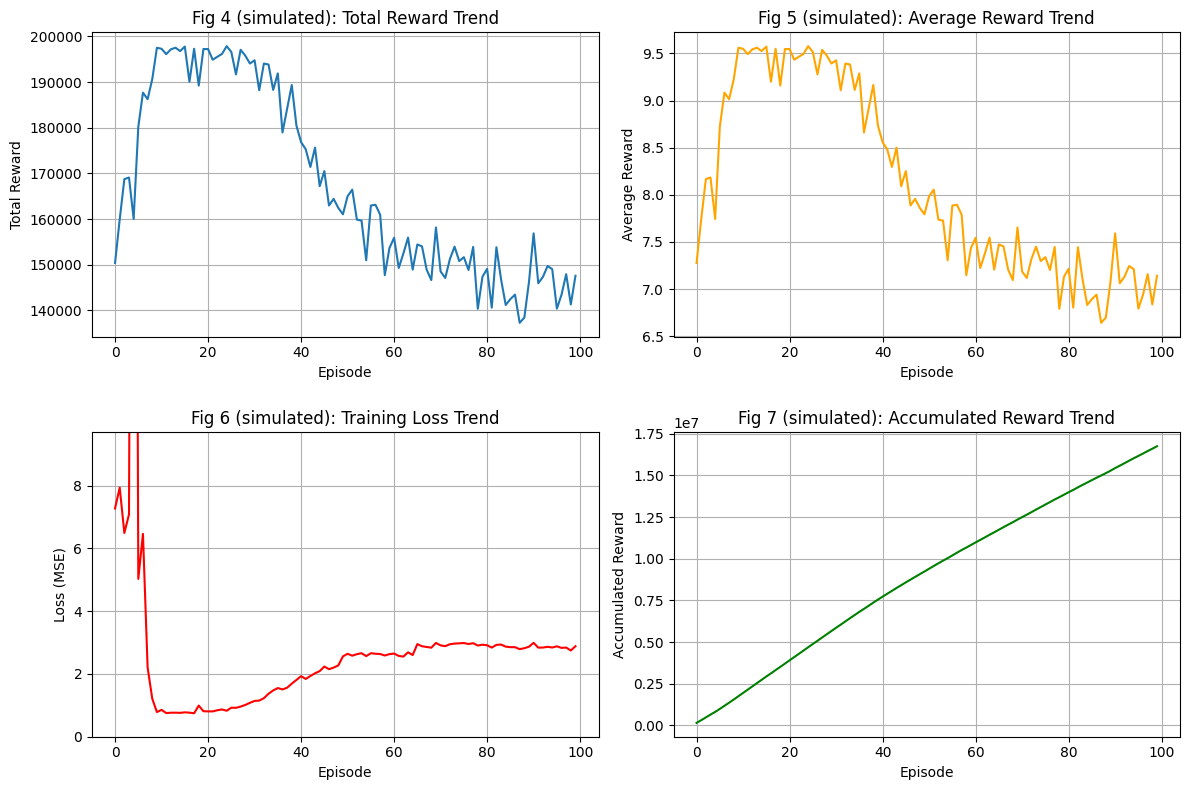

In [ ]:
run(X_train, X_test, y_train, y_test, EPISODES=100)

Using device: cpu

--- Starting DDQN Training ---
Episode: 1/10, Total Reward: 151509, Avg Reward: 7.33, Epsilon: 0.33, Avg Loss: 7.2473
Episode: 2/10, Total Reward: 159000, Avg Reward: 7.69, Epsilon: 0.26, Avg Loss: 10.2714
Episode: 3/10, Total Reward: 167888, Avg Reward: 8.13, Epsilon: 0.22, Avg Loss: 6.3509
Episode: 4/10, Total Reward: 173729, Avg Reward: 8.41, Epsilon: 0.18, Avg Loss: 7.0916
Episode: 5/10, Total Reward: 177986, Avg Reward: 8.61, Epsilon: 0.14, Avg Loss: 3.8523
Episode: 6/10, Total Reward: 185950, Avg Reward: 9.00, Epsilon: 0.12, Avg Loss: 3.8354
Episode: 7/10, Total Reward: 185730, Avg Reward: 8.99, Epsilon: 0.09, Avg Loss: 1.0879
Episode: 8/10, Total Reward: 192374, Avg Reward: 9.31, Epsilon: 0.08, Avg Loss: 1.4534
Episode: 9/10, Total Reward: 193485, Avg Reward: 9.36, Epsilon: 0.06, Avg Loss: 1.2132
Episode: 10/10, Total Reward: 196752, Avg Reward: 9.52, Epsilon: 0.05, Avg Loss: 1.6179

--- Training Finished in 450.03 seconds ---

--- Evaluating on Test Set ---
T

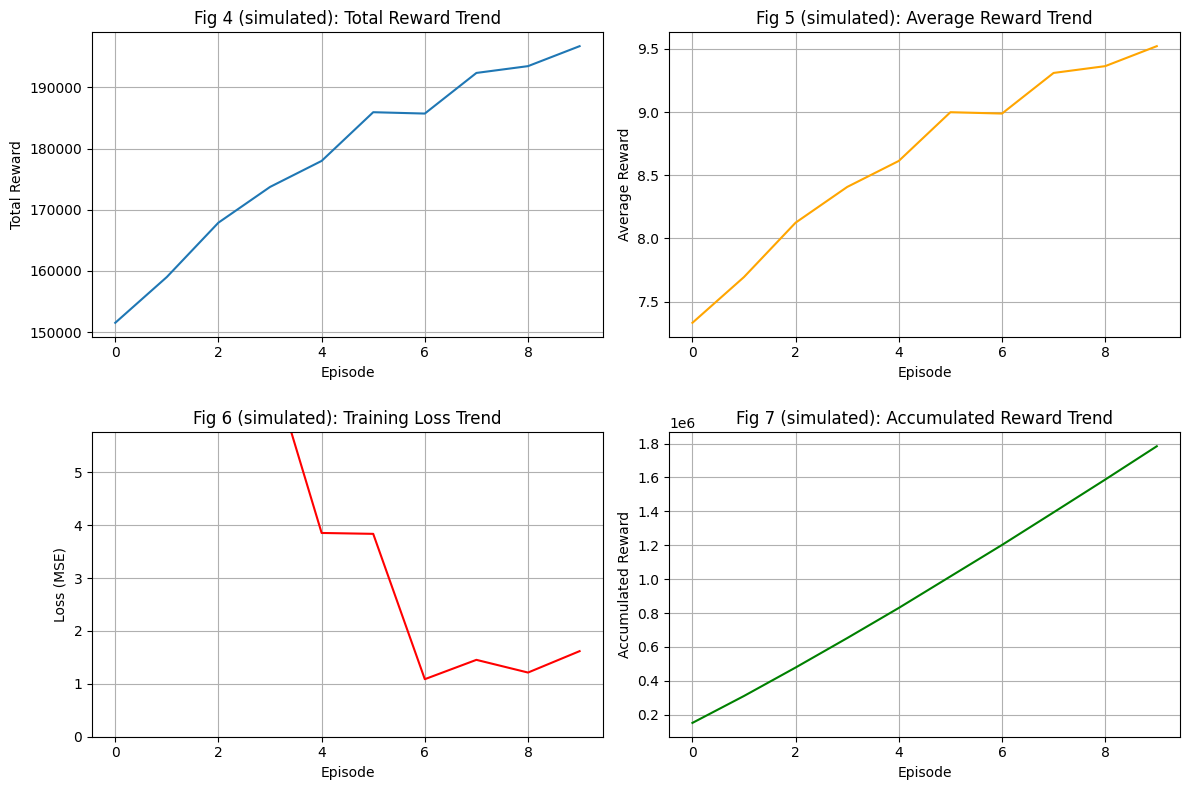

In [ ]:
run(X_train, X_test, y_train, y_test, EPISODES=10)

Using device: cpu

--- Starting DDQN Training ---
Episode: 1/50, Total Reward: 150871, Avg Reward: 7.30, Epsilon: 0.33, Avg Loss: 7.3263
Episode: 2/50, Total Reward: 159913, Avg Reward: 7.74, Epsilon: 0.26, Avg Loss: 9.7373
Episode: 3/50, Total Reward: 169021, Avg Reward: 8.18, Epsilon: 0.22, Avg Loss: 7.3231
Episode: 4/50, Total Reward: 175610, Avg Reward: 8.50, Epsilon: 0.18, Avg Loss: 5.7158
Episode: 5/50, Total Reward: 180494, Avg Reward: 8.74, Epsilon: 0.14, Avg Loss: 4.4222
Episode: 6/50, Total Reward: 184278, Avg Reward: 8.92, Epsilon: 0.12, Avg Loss: 4.0408
Episode: 7/50, Total Reward: 113119, Avg Reward: 5.47, Epsilon: 0.09, Avg Loss: 4.0930
Episode: 8/50, Total Reward: 162476, Avg Reward: 7.86, Epsilon: 0.08, Avg Loss: 21.9303
Episode: 9/50, Total Reward: 192594, Avg Reward: 9.32, Epsilon: 0.06, Avg Loss: 4.8871
Episode: 10/50, Total Reward: 82737, Avg Reward: 4.00, Epsilon: 0.05, Avg Loss: 14.3949
Episode: 11/50, Total Reward: 198996, Avg Reward: 9.63, Epsilon: 0.05, Avg Los

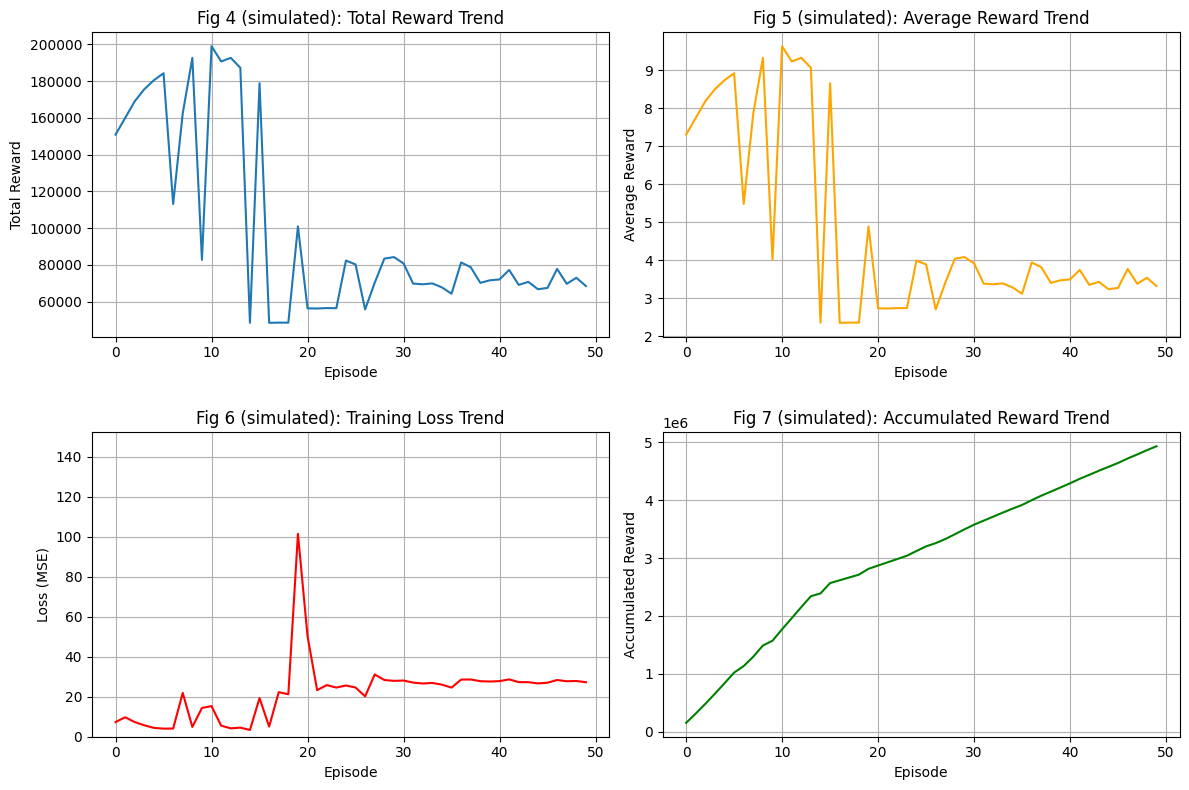

In [ ]:
run(X_train, X_test, y_train, y_test, EPISODES=50)

In [ ]:
X = np.load()
y = np.load('Full_dataset_y.npy')

In [ ]:
X_train = X[train_index]
y_train = y[train_index]

X_test = X[test_index]
y_test = y[test_index]

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

Train_Test split

In [ ]:
# --- 6. MAIN TRAINING AND EVALUATION SCRIPT ---
def run2(features, labels) :
    EPISODES = 100
    UPDATE_TARGET_EVERY = 5


    X_train, X_test, y_train, y_test = train_test_split(features, labels, test_size=0.2, random_state=42)

    train_env = AttentionEnv(X_train, y_train)
    state_size = train_env.state_shape[0]
    action_size = train_env.action_space_n
    agent = DDQNAgent(state_size, action_size)

    training_history = {'total_reward': [], 'avg_reward': [], 'loss': []}
    start_time = time.time()

    print("\n--- Starting DDQN Training ---")
    for e in range(EPISODES):
        state = train_env.reset()
        total_reward, total_loss, steps = 0, 0, 0
        done = False

        while not done:
            action = agent.act(state)
            next_state, reward, done, _ = train_env.step(action)

            agent.remember(state, action, reward, next_state, done)

            state = next_state
            total_reward += reward
            steps += 1
            if steps % 1 == 0 :
                loss = agent.replay()
                total_loss += loss

            if steps % 100 == 0 :
                # Decay epsilon
                if agent.epsilon > agent.epsilon_min:
                    agent.epsilon *= agent.epsilon_decay

        if e % UPDATE_TARGET_EVERY == 0:
            agent.update_target_net()


        avg_loss = total_loss / steps if steps > 0 else 0
        avg_reward = total_reward / steps if steps > 0 else 0

        training_history['total_reward'].append(total_reward)
        training_history['avg_reward'].append(avg_reward)
        training_history['loss'].append(avg_loss)

        print(f"Episode: {e+1}/{EPISODES}, Total Reward: {total_reward}, Avg Reward: {avg_reward:.2f}, Epsilon: {agent.epsilon:.2f}, Avg Loss: {avg_loss:.4f}")

    end_time = time.time()
    print(f"\n--- Training Finished in {end_time - start_time:.2f} seconds ---")

    # --- Evaluation ---
    print("\n--- Evaluating on Test Set ---")
    correct_predictions = 0
    total_test_samples = len(X_test)
    agent.epsilon = 0.0 # Turn off exploration

    for i in range(total_test_samples):
        state = X_test[i]
        action = agent.act(state)
        if action == y_test[i]:
            correct_predictions += 1

    accuracy = (correct_predictions / total_test_samples) * 100
    print(f"Test Accuracy: {accuracy:.2f}%")

    # --- Visualization ---
    plot_results(training_history)

In [ ]:
X = np.load('channel_19_dataset_X.npy')
y = np.load('channel_19_dataset_y.npy')

In [ ]:
X = X.reshape(30000,19*385)

Using device: cpu

--- Starting DDQN Training ---
Episode: 1/20, Total Reward: 74242, Avg Reward: 3.09, Epsilon: 0.24, Avg Loss: 4.2022
Episode: 2/20, Total Reward: 91336, Avg Reward: 3.81, Epsilon: 0.19, Avg Loss: 3.6552
Episode: 3/20, Total Reward: 100983, Avg Reward: 4.21, Epsilon: 0.15, Avg Loss: 3.5107
Episode: 4/20, Total Reward: 113666, Avg Reward: 4.74, Epsilon: 0.12, Avg Loss: 3.2319
Episode: 5/20, Total Reward: 113974, Avg Reward: 4.75, Epsilon: 0.09, Avg Loss: 4.1205
Episode: 6/20, Total Reward: 126712, Avg Reward: 5.28, Epsilon: 0.07, Avg Loss: 3.5038
Episode: 7/20, Total Reward: 134742, Avg Reward: 5.61, Epsilon: 0.06, Avg Loss: 3.3933
Episode: 8/20, Total Reward: 137646, Avg Reward: 5.74, Epsilon: 0.04, Avg Loss: 4.4966
Episode: 9/20, Total Reward: 141243, Avg Reward: 5.89, Epsilon: 0.03, Avg Loss: 4.2365
Episode: 10/20, Total Reward: 147227, Avg Reward: 6.13, Epsilon: 0.03, Avg Loss: 3.7831
Episode: 11/20, Total Reward: 149900, Avg Reward: 6.25, Epsilon: 0.02, Avg Loss: 

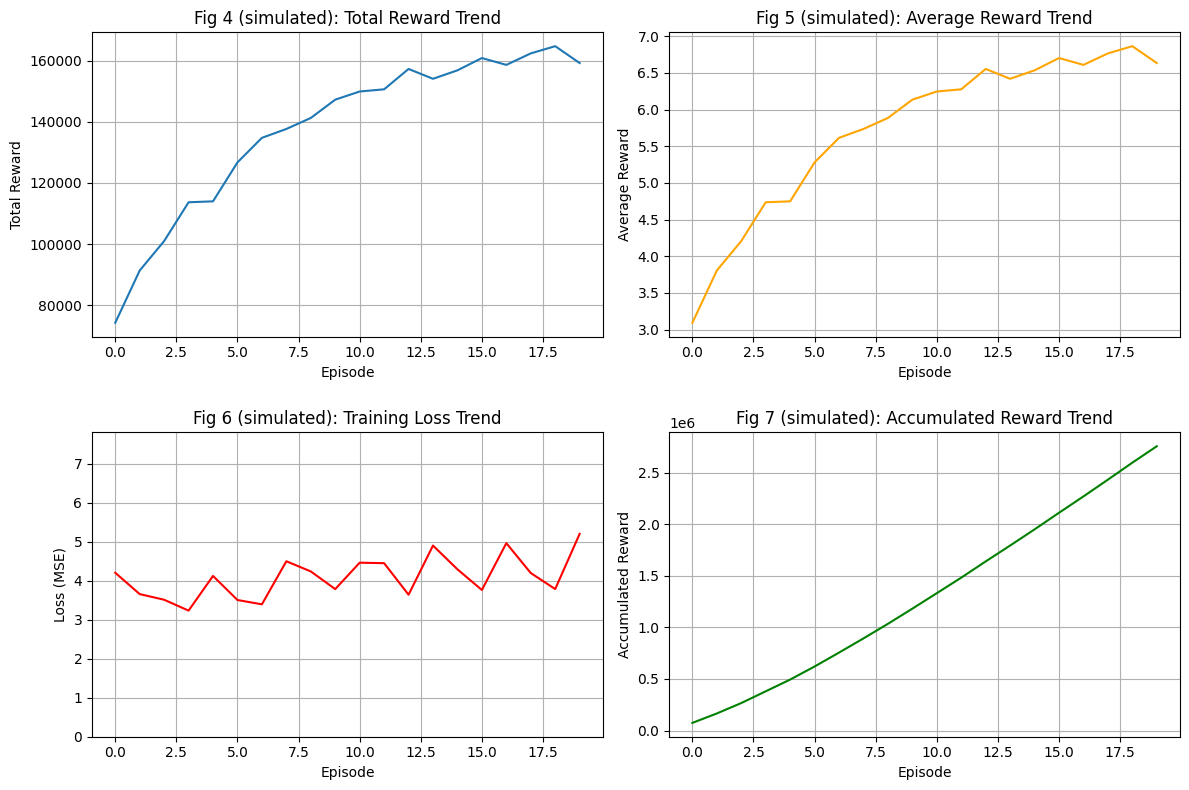

In [ ]:
run2(X,y)

Using device: cpu

--- Starting DDQN Training ---
Episode: 1/50, Total Reward: 73989, Avg Reward: 3.08, Epsilon: 0.31, Avg Loss: 3.6450
Episode: 2/50, Total Reward: 90423, Avg Reward: 3.77, Epsilon: 0.25, Avg Loss: 3.3663
Episode: 3/50, Total Reward: 102710, Avg Reward: 4.28, Epsilon: 0.20, Avg Loss: 3.1487
Episode: 4/50, Total Reward: 114535, Avg Reward: 4.77, Epsilon: 0.15, Avg Loss: 2.9451
Episode: 5/50, Total Reward: 117318, Avg Reward: 4.89, Epsilon: 0.12, Avg Loss: 4.0225
Episode: 6/50, Total Reward: 127009, Avg Reward: 5.29, Epsilon: 0.10, Avg Loss: 3.5223
Episode: 7/50, Total Reward: 136018, Avg Reward: 5.67, Epsilon: 0.08, Avg Loss: 3.3352
Episode: 8/50, Total Reward: 141056, Avg Reward: 5.88, Epsilon: 0.06, Avg Loss: 3.9734
Episode: 9/50, Total Reward: 147568, Avg Reward: 6.15, Epsilon: 0.05, Avg Loss: 3.5154
Episode: 10/50, Total Reward: 151770, Avg Reward: 6.32, Epsilon: 0.05, Avg Loss: 3.2323
Episode: 11/50, Total Reward: 150428, Avg Reward: 6.27, Epsilon: 0.05, Avg Loss: 

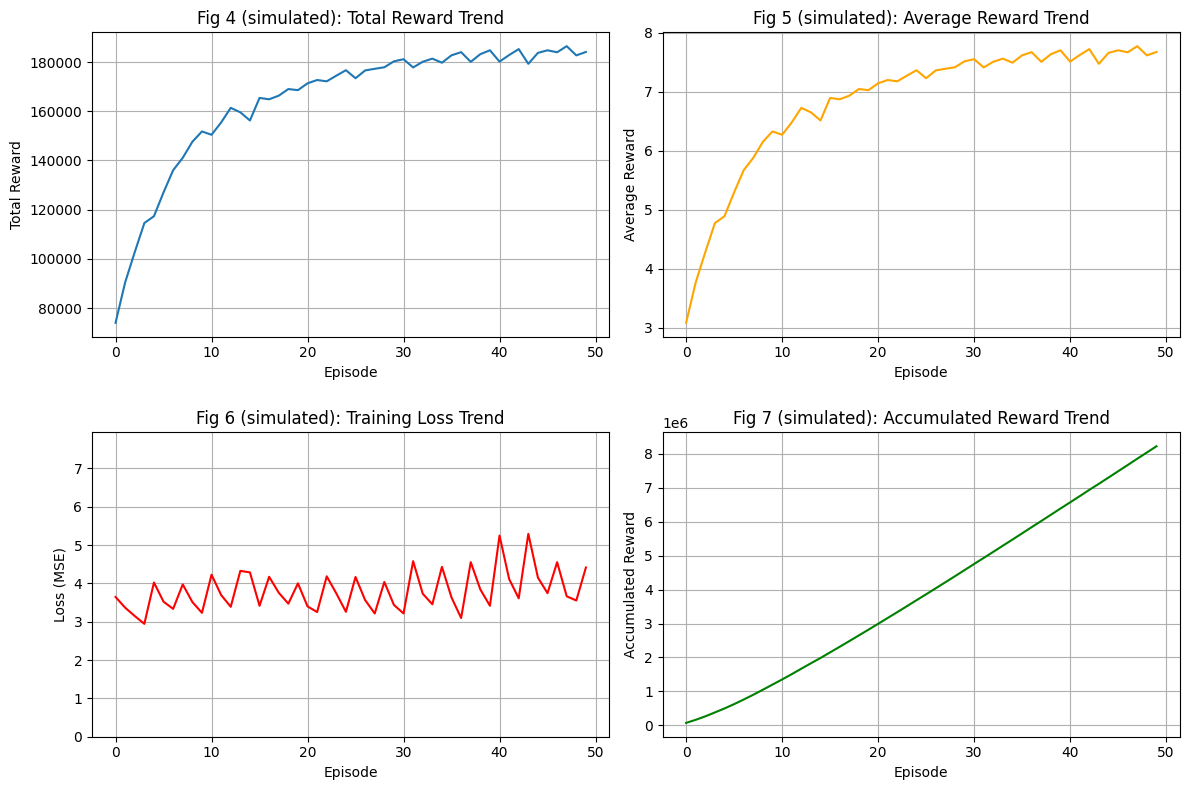

In [ ]:
run2(X,y)

Using device: cpu

--- Starting DDQN Training ---
Episode: 1/10, Total Reward: 85924, Avg Reward: 3.58, Epsilon: 0.01, Avg Loss: 20.3616
Episode: 2/10, Total Reward: 111345, Avg Reward: 4.64, Epsilon: 0.01, Avg Loss: 22.7943
Episode: 3/10, Total Reward: 123896, Avg Reward: 5.16, Epsilon: 0.01, Avg Loss: 16.8078
Episode: 4/10, Total Reward: 133785, Avg Reward: 5.57, Epsilon: 0.01, Avg Loss: 13.6927
Episode: 5/10, Total Reward: 137228, Avg Reward: 5.72, Epsilon: 0.01, Avg Loss: 13.1113
Episode: 6/10, Total Reward: 138867, Avg Reward: 5.79, Epsilon: 0.01, Avg Loss: 11.3769
Episode: 7/10, Total Reward: 140451, Avg Reward: 5.85, Epsilon: 0.01, Avg Loss: 10.8035
Episode: 8/10, Total Reward: 141419, Avg Reward: 5.89, Epsilon: 0.01, Avg Loss: 10.5172
Episode: 9/10, Total Reward: 142651, Avg Reward: 5.94, Epsilon: 0.01, Avg Loss: 10.5460
Episode: 10/10, Total Reward: 142299, Avg Reward: 5.93, Epsilon: 0.01, Avg Loss: 9.6124

--- Training Finished in 681.12 seconds ---

--- Evaluating on Test Se

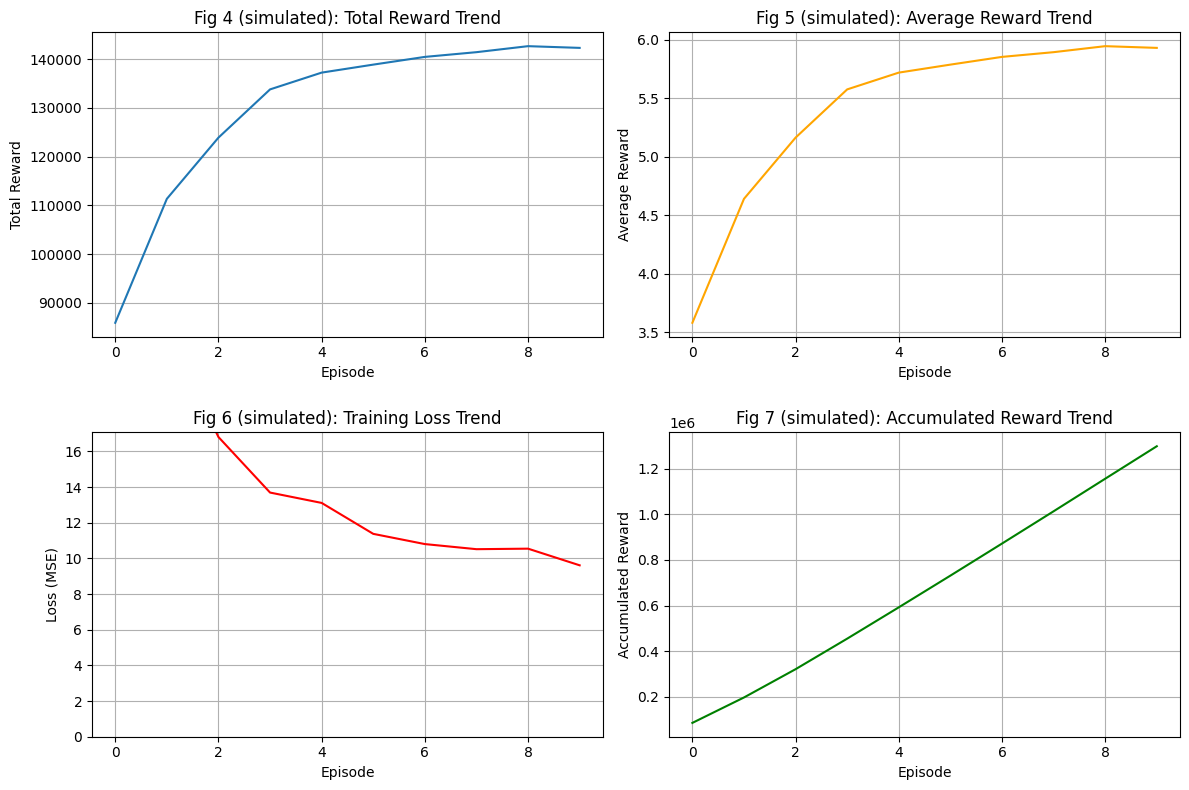

In [ ]:
run2(X,y)

Using device: cpu

--- Starting DDQN Training ---
Episode: 1/20, Total Reward: 83042, Avg Reward: 3.46, Epsilon: 0.01, Avg Loss: 20.8289
Episode: 2/20, Total Reward: 111070, Avg Reward: 4.63, Epsilon: 0.01, Avg Loss: 24.7904
Episode: 3/20, Total Reward: 118363, Avg Reward: 4.93, Epsilon: 0.01, Avg Loss: 19.6642
Episode: 4/20, Total Reward: 130056, Avg Reward: 5.42, Epsilon: 0.01, Avg Loss: 16.7758
Episode: 5/20, Total Reward: 135435, Avg Reward: 5.64, Epsilon: 0.01, Avg Loss: 13.8371
Episode: 6/20, Total Reward: 139274, Avg Reward: 5.80, Epsilon: 0.01, Avg Loss: 12.3368
Episode: 7/20, Total Reward: 137129, Avg Reward: 5.71, Epsilon: 0.01, Avg Loss: 20.9803
Episode: 8/20, Total Reward: 139054, Avg Reward: 5.79, Epsilon: 0.01, Avg Loss: 15.9436
Episode: 9/20, Total Reward: 140594, Avg Reward: 5.86, Epsilon: 0.01, Avg Loss: 15.1533
Episode: 10/20, Total Reward: 141144, Avg Reward: 5.88, Epsilon: 0.01, Avg Loss: 13.8378
Episode: 11/20, Total Reward: 141441, Avg Reward: 5.89, Epsilon: 0.01,

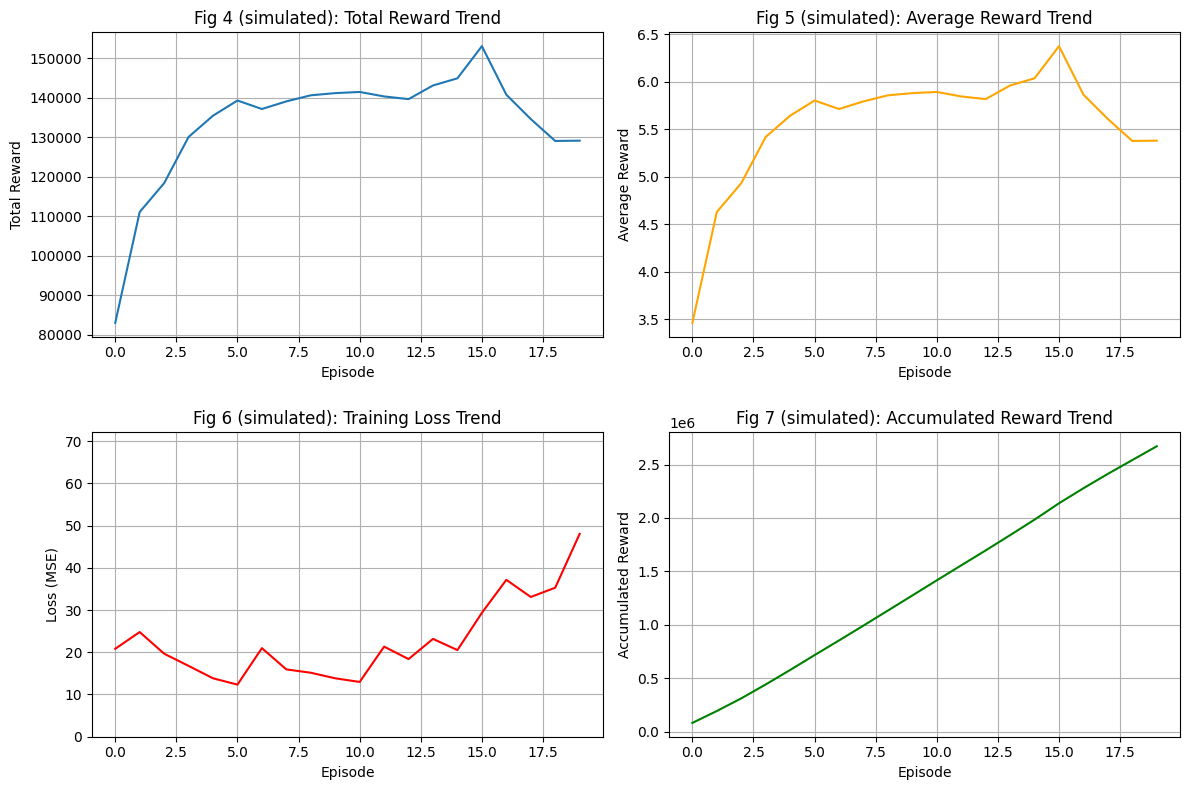

In [ ]:
run2(X,y)

Using device: cpu

--- Starting DDQN Training ---
Episode: 1/50, Total Reward: 69831, Avg Reward: 2.91, Epsilon: 0.39, Avg Loss: 4.3983
Episode: 2/50, Total Reward: 78851, Avg Reward: 3.29, Epsilon: 0.38, Avg Loss: 3.3643
Episode: 3/50, Total Reward: 83768, Avg Reward: 3.49, Epsilon: 0.37, Avg Loss: 3.1509
Episode: 4/50, Total Reward: 90764, Avg Reward: 3.78, Epsilon: 0.36, Avg Loss: 3.0803
Episode: 5/50, Total Reward: 96198, Avg Reward: 4.01, Epsilon: 0.36, Avg Loss: 3.7036
Episode: 6/50, Total Reward: 99630, Avg Reward: 4.15, Epsilon: 0.35, Avg Loss: 3.4454
Episode: 7/50, Total Reward: 105845, Avg Reward: 4.41, Epsilon: 0.34, Avg Loss: 3.2828
Episode: 8/50, Total Reward: 111653, Avg Reward: 4.65, Epsilon: 0.33, Avg Loss: 3.6944
Episode: 9/50, Total Reward: 115976, Avg Reward: 4.83, Epsilon: 0.33, Avg Loss: 3.2796
Episode: 10/50, Total Reward: 120827, Avg Reward: 5.03, Epsilon: 0.32, Avg Loss: 3.0621
Episode: 11/50, Total Reward: 122004, Avg Reward: 5.08, Epsilon: 0.31, Avg Loss: 3.98

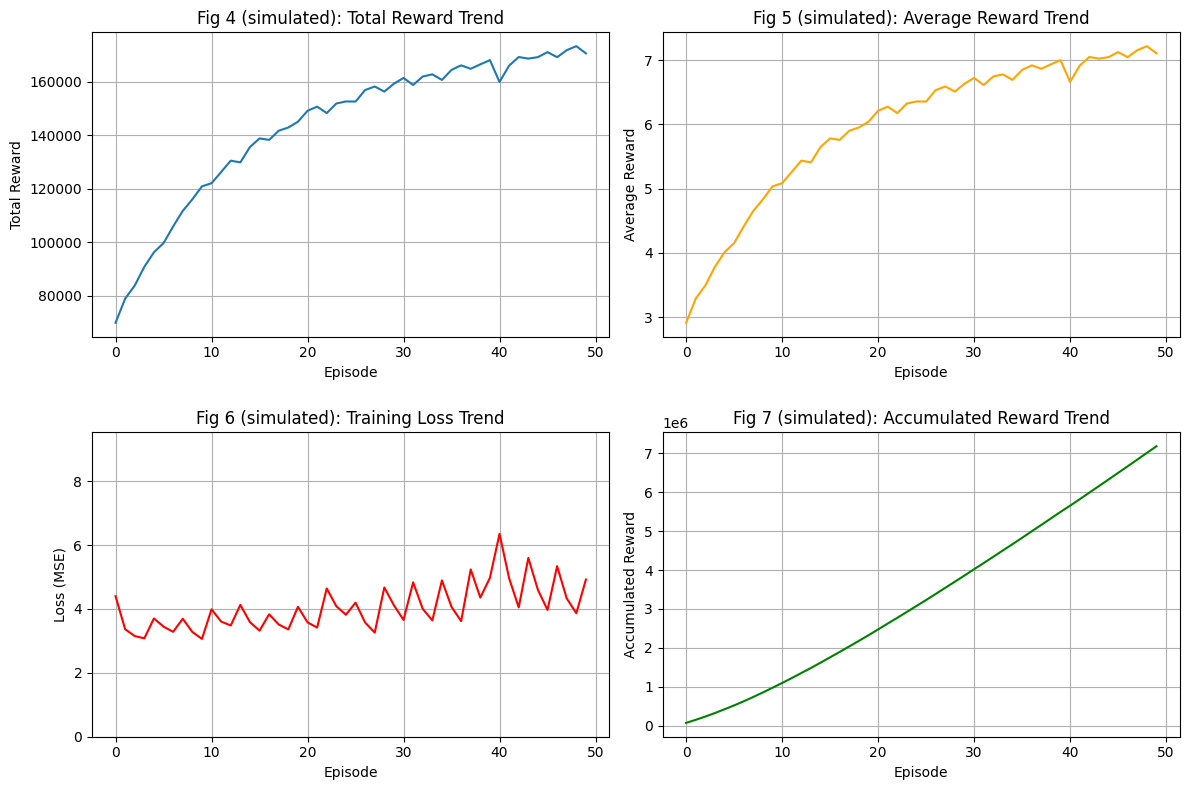

In [ ]:
run2(X,y)

In [ ]:
run2(X,y)

Using device: cpu

--- Starting DDQN Training ---
Episode: 1/100, Total Reward: 63704, Avg Reward: 2.65, Epsilon: 0.31, Avg Loss: 41.7865
Episode: 2/100, Total Reward: 62956, Avg Reward: 2.62, Epsilon: 0.25, Avg Loss: 28.0422
Episode: 3/100, Total Reward: 64320, Avg Reward: 2.68, Epsilon: 0.20, Avg Loss: 27.0183
Episode: 4/100, Total Reward: 63462, Avg Reward: 2.64, Epsilon: 0.15, Avg Loss: 26.8237
Episode: 5/100, Total Reward: 63506, Avg Reward: 2.65, Epsilon: 0.12, Avg Loss: 26.8175
Episode: 6/100, Total Reward: 64265, Avg Reward: 2.68, Epsilon: 0.10, Avg Loss: 26.9529
Episode: 7/100, Total Reward: 63847, Avg Reward: 2.66, Epsilon: 0.08, Avg Loss: 27.5033
Episode: 8/100, Total Reward: 64133, Avg Reward: 2.67, Epsilon: 0.06, Avg Loss: 26.9664
Episode: 9/100, Total Reward: 64210, Avg Reward: 2.68, Epsilon: 0.05, Avg Loss: 26.9451
Episode: 10/100, Total Reward: 64243, Avg Reward: 2.68, Epsilon: 0.05, Avg Loss: 26.9379


KeyboardInterrupt: 

In [ ]:
def load_your_eeg_dataset56():
    X = np.load('Balanced_dataset_X.npy')
    y = np.load('Balanced_dataset_y.npy')
    dataset = [ (X[i] , y[i] )for i in range(len(X))]
    return dataset
def load_your_test_dataset56():
    X = np.load('Test_dataset_X.npy')
    y = np.load('Test_dataset_y.npy')
    dataset = [ (X[i] , y[i] )for i in range(len(X))]
    return dataset

In [ ]:
# --- 6. MAIN TRAINING AND EVALUATION SCRIPT ---
def run56(features, labels) :
    EPISODES = 100
    UPDATE_TARGET_EVERY = 5


    X_train, X_test, y_train, y_test = train_test_split(features, labels, test_size=0.2, random_state=42)

    train_env = AttentionEnv(X_train, y_train)
    state_size = train_env.state_shape[0]
    action_size = train_env.action_space_n
    agent = DDQNAgent(state_size, action_size)

    training_history = {'total_reward': [], 'avg_reward': [], 'loss': []}
    start_time = time.time()

    print("\n--- Starting DDQN Training ---")
    for e in range(EPISODES):
        state = train_env.reset()
        total_reward, total_loss, steps = 0, 0, 0
        done = False

        while not done:
            action = agent.act(state)
            next_state, reward, done, _ = train_env.step(action)

            agent.remember(state, action, reward, next_state, done)

            state = next_state
            total_reward += reward
            steps += 1
            if steps % 1 == 0 :
                loss = agent.replay()
                total_loss += loss

            if steps % 100 == 0 :
                # Decay epsilon
                if agent.epsilon > agent.epsilon_min:
                    agent.epsilon *= agent.epsilon_decay

        if e % UPDATE_TARGET_EVERY == 0:
            agent.update_target_net()


        avg_loss = total_loss / steps if steps > 0 else 0
        avg_reward = total_reward / steps if steps > 0 else 0

        training_history['total_reward'].append(total_reward)
        training_history['avg_reward'].append(avg_reward)
        training_history['loss'].append(avg_loss)

        print(f"Episode: {e+1}/{EPISODES}, Total Reward: {total_reward}, Avg Reward: {avg_reward:.2f}, Epsilon: {agent.epsilon:.2f}, Avg Loss: {avg_loss:.4f}")

    end_time = time.time()
    print(f"\n--- Training Finished in {end_time - start_time:.2f} seconds ---")

    # --- Evaluation ---
    print("\n--- Evaluating on Test Set ---")
    correct_predictions = 0
    total_test_samples = len(X_test)
    agent.epsilon = 0.0 # Turn off exploration

    for i in range(total_test_samples):
        state = X_test[i]
        action = agent.act(state)
        if action == y_test[i]:
            correct_predictions += 1

    accuracy = (correct_predictions / total_test_samples) * 100
    print(f"Test Accuracy: {accuracy:.2f}%")

    # --- Visualization ---
    plot_results(training_history)

In [ ]:
X = np.load('Balanced_dataset_X.npy')
y = np.load('Balanced_dataset_y.npy')

In [ ]:
X = X.reshape(30000,56*385)

In [ ]:
run56(X,y)

Using device: cpu

--- Starting DDQN Training ---
Episode: 1/100, Total Reward: 63858, Avg Reward: 2.66, Epsilon: 0.31, Avg Loss: 63.4525
Episode: 2/100, Total Reward: 63979, Avg Reward: 2.67, Epsilon: 0.25, Avg Loss: 28.4780
Episode: 3/100, Total Reward: 63693, Avg Reward: 2.65, Epsilon: 0.20, Avg Loss: 26.9003
Episode: 4/100, Total Reward: 63792, Avg Reward: 2.66, Epsilon: 0.15, Avg Loss: 26.8674
Episode: 5/100, Total Reward: 63979, Avg Reward: 2.67, Epsilon: 0.12, Avg Loss: 26.9003
Episode: 6/100, Total Reward: 63385, Avg Reward: 2.64, Epsilon: 0.10, Avg Loss: 26.8016


KeyboardInterrupt: 

In [ ]:
# --- 1. Generate Dummy EEG Data ---
def generate_dummy_eeg_data(sampling_rate_hz=250, duration_seconds=10, num_channels=4):
    """
    Generates synthetic EEG-like data for demonstration.
    Simulates different brainwave frequencies (delta, theta, alpha, beta, gamma).
    """
    time = np.linspace(0, duration_seconds, int(sampling_rate_hz * duration_seconds), endpoint=False)
    eeg_data = np.zeros((num_channels, len(time)))

    # Define common EEG frequency bands (approximate)
    # Delta: 1-4 Hz (e.g., sleep)
    # Theta: 4-8 Hz (e.g., drowsiness, meditation)
    # Alpha: 8-13 Hz (e.g., relaxed, awake)
    # Beta: 13-30 Hz (e.g., active thinking, concentration)
    # Gamma: 30-100 Hz (e.g., high-level cognitive processing)

    frequencies = [
        [2, 6, 10, 20],  # Channel 1: Mix of frequencies
        [3, 7, 12, 18],  # Channel 2: Another mix
        [5, 9, 15, 25],  # Channel 3: Yet another mix
        [4, 8, 11, 22]   # Channel 4: Final mix
    ]
    amplitudes = [
        [0.8, 0.5, 0.3, 0.1], # Amplitudes for Channel 1
        [0.7, 0.6, 0.4, 0.2], # Amplitudes for Channel 2
        [0.6, 0.7, 0.5, 0.3], # Amplitudes for Channel 3
        [0.9, 0.4, 0.2, 0.1]  # Amplitudes for Channel 4
    ]

    for i in range(num_channels):
        for j in range(len(frequencies[i])):
            eeg_data[i] += amplitudes[i][j] * np.sin(2 * np.pi * frequencies[i][j] * time + np.random.rand() * 2 * np.pi)
        # Add some random noise
        eeg_data[i] += 0.2 * np.random.randn(len(time))

    print(f"Generated dummy EEG data with shape: {eeg_data.shape} (Channels x Samples)")
    return eeg_data, sampling_rate_hz, time

In [ ]:
# --- 2. Power Spectral Density (PSD) Extraction ---
def extract_psd(eeg_data, sampling_rate_hz):
    """
    Extracts Power Spectral Density (PSD) using Welch's method.
    PSD represents the power of the signal as a function of frequency.

    Args:
        eeg_data (np.ndarray): 1D array of EEG signal for a single channel, or 2D array (channels x samples).
        sampling_rate_hz (int): Sampling rate of the EEG data in Hz.

    Returns:
        tuple: (frequencies, psd_values)
            frequencies (np.ndarray): Array of frequencies (Hz).
            psd_values (np.ndarray): Array of power spectral density values (V^2/Hz).
                                     If eeg_data is 2D, psd_values will be (channels x frequencies).
    """
    if eeg_data.ndim == 1:
        frequencies, psd_values = welch(eeg_data, fs=sampling_rate_hz, nperseg=sampling_rate_hz * 2) # 2-second segments
    else: # Multi-channel data
        num_channels = eeg_data.shape[0]
        psd_values = []
        frequencies = None
        for i in range(num_channels):
            f, p = welch(eeg_data[i], fs=sampling_rate_hz, nperseg=sampling_rate_hz * 2)
            if frequencies is None:
                frequencies = f
            psd_values.append(p)
        psd_values = np.array(psd_values)

    print(f"Extracted PSD with shape: {psd_values.shape}")
    return frequencies, psd_values

In [ ]:
# --- 3. Discrete Wavelet Transform (DWT) Coefficient Extraction ---
def extract_dwt_coefficients(eeg_data, wavelet='db4', level=5):
    """
    Extracts Discrete Wavelet Transform (DWT) coefficients.
    DWT decomposes the signal into approximation and detail coefficients
    at different scales (levels), capturing features at various frequency
    bands implicitly.

    Args:
        eeg_data (np.ndarray): 1D array of EEG signal for a single channel, or 2D array (channels x samples).
        wavelet (str): Name of the wavelet to use (e.g., 'db4', 'haar', 'sym5').
                       See pywt.wavelist() for available wavelets.
        level (int): Decomposition level. Higher levels correspond to coarser approximations
                     and finer details.

    Returns:
        list or list of lists: DWT coefficients. Each element is a tuple (cD_n, ..., cD_1, cA_n).
                              If eeg_data is 2D, returns a list of coefficient lists for each channel.
    """
    if eeg_data.ndim == 1:
        coeffs = pywt.wavedec(eeg_data, wavelet, level=level)
        print(f"Extracted DWT coefficients for single channel with {len(coeffs)} components.")
        # Example of how to access coefficients: cA_level, cD_level, ..., cD1
        # print(f"  Approx Coeffs (cA{level}) shape: {coeffs[0].shape}")
        # print(f"  Detail Coeffs (cD{level}) shape: {coeffs[1].shape}")
    else: # Multi-channel data
        num_channels = eeg_data.shape[0]
        all_coeffs = []
        for i in range(num_channels):
            coeffs = pywt.wavedec(eeg_data[i], wavelet, level=level)
            all_coeffs.append(coeffs)
        print(f"Extracted DWT coefficients for {num_channels} channels. Each channel has {len(all_coeffs[0])} components.")
        # print(f"  Example: Channel 0, Approx Coeffs (cA{level}) shape: {all_coeffs[0][0].shape}")
        # print(f"  Example: Channel 0, Detail Coeffs (cD{level}) shape: {all_coeffs[0][1].shape}")
        return all_coeffs

    return coeffs

In [ ]:
def extract_features (eeg_data_channels, time_vector , sr=250 ,num_eeg_channels=19) :
    # Parameters for dummy data generation
    sampling_rate = 250  # Hz
    duration = 10        # seconds


    # Generate dummy EEG data
    #eeg_data_channels, sr, time_vector = generate_dummy_eeg_data(
    #    sampling_rate_hz=sampling_rate,
    #    duration_seconds=duration,
    #    num_channels=num_eeg_channels
    #)

    # Select a single channel for detailed demonstration if needed
    # For this example, we'll process all channels in the functions directly.
    eeg_channel_0 = eeg_data_channels[0]

    print("\n--- Performing PSD Extraction ---")
    frequencies_psd, psd_values_all_channels = extract_psd(eeg_data_channels, sr)

    print("\n--- Performing DWT Coefficient Extraction ---")
    # Choose a wavelet and decomposition level
    # Common choices: 'db4', 'sym8', 'haar'
    # Level depends on signal length and desired frequency resolution
    wavelet_name = 'db4'
    dwt_level = 5
    dwt_coefficients_all_channels = extract_dwt_coefficients(eeg_data_channels, wavelet=wavelet_name, level=dwt_level)

    return frequencies_psd , psd_values_all_channels , dwt_coefficients_all_channels

In [ ]:
def visualize_features(frequencies_psd , psd_values_all_channels , dwt_coefficients_all_channels ,eeg_data_channels, time_vector , sr=250,num_eeg_channels=19) :

    wavelet_name = 'db4'
    dwt_level = 5
    eeg_channel_0 = eeg_data_channels[0]

    # --- Visualization (Optional) ---
    print("\n--- Plotting Results ---")

    # Plot Raw EEG Data for first channel
    plt.figure(figsize=(12, 12))
    plt.subplot(3, 1, 1)
    plt.plot(time_vector, eeg_channel_0)
    plt.title(f'Raw EEG Data - Channel 0 (Simulated)')
    plt.xlabel('Time (seconds)')
    plt.ylabel('Amplitude')
    plt.grid(True)

    # Plot PSD for all channels
    plt.subplot(3, 1, 2)
    for i in range(num_eeg_channels):
        plt.plot(frequencies_psd, 10 * np.log10(psd_values_all_channels[i]), label=f'Channel {i}')
    plt.title('Power Spectral Density (PSD) for EEG Channels')
    plt.xlabel('Frequency (Hz)')
    plt.ylabel('Power/Frequency (dB/Hz)')
    plt.xlim(0, 300) # Focus on typical EEG frequency range
    plt.legend()
    plt.grid(True)

    plt.subplot(3, 1, 3)
    for i in range(num_eeg_channels):
        plt.plot(frequencies_psd, 10 * np.log10(psd_values_all_channels[i]), label=f'Channel {i}')
    plt.title('Power Spectral Density (PSD) for EEG Channels')
    plt.xlabel('Frequency (Hz)')
    plt.ylabel('Power/Frequency (dB/Hz)')
    plt.xlim(0, 50) # Focus on typical EEG frequency range
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # Plot DWT coefficients for the first channel (example for cA5 and cD5)
    if isinstance(dwt_coefficients_all_channels, list) and isinstance(dwt_coefficients_all_channels[0], list):
        # Assuming multi-channel output, take the first channel's coeffs
        first_channel_coeffs = dwt_coefficients_all_channels[0]
    else:
        # Assuming single-channel output
        first_channel_coeffs = dwt_coefficients_all_channels

    # cA_level is the first element, cD_level is the second
    cA_n = first_channel_coeffs[0]
    cD_n = first_channel_coeffs[1] # cD_level (highest frequency detail)

    plt.figure(figsize=(12, 6))
    plt.subplot(2, 1, 1)
    plt.plot(cA_n)
    plt.title(f'DWT Approximation Coefficients (cA{dwt_level}) - Channel 0')
    plt.xlabel('Coefficient Index')
    plt.ylabel('Amplitude')
    plt.grid(True)

    plt.subplot(2, 1, 2)
    plt.plot(cD_n)
    plt.title(f'DWT Detail Coefficients (cD{dwt_level}) - Channel 0')
    plt.xlabel('Coefficient Index')
    plt.ylabel('Amplitude')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    print("\nFeature extraction complete. Plots displayed (if running in an environment with GUI support).")
    print("You can inspect 'psd_values_all_channels' and 'dwt_coefficients_all_channels' variables.")


In [ ]:
def load_your_eeg_dataset():
    X = np.load('channel_19_dataset_X.npy')
    y = np.load('channel_19_dataset_y.npy')
    dataset = [ (X[i] , y[i] )for i in range(len(X))]
    return dataset
def load_your_test_dataset():
    X = np.load('channel_19_test_dataset_X.npy')
    y = np.load('channel_19_test_dataset_y.npy')
    dataset = [ (X[i] , y[i] )for i in range(len(X))]
    return dataset

In [ ]:
time = np.linspace(0, 10, int(385), endpoint=False)

In [ ]:
frequencies_psd , psd_values_all_channels , dwt_coefficients_all_channels = extract_features (X[0], time , sr=500 ,num_eeg_channels=19)


--- Performing PSD Extraction ---
Extracted PSD with shape: (19, 193)

--- Performing DWT Coefficient Extraction ---
Extracted DWT coefficients for 19 channels. Each channel has 6 components.


/var/folders/6x/z0_0651n5712p67md5wx1fpm0000gn/T/ipykernel_3595/3131581612.py:24: UserWarning: nperseg=1000 is greater than signal length max(len(x), len(y)) = 385, using nperseg = 385
  f, p = welch(eeg_data[i], fs=sampling_rate_hz, nperseg=sampling_rate_hz * 2)


In [ ]:
psd_values_all_channels

array([[2.38900971e+00, 1.33063602e+01, 5.27097206e+01, ...,
        9.50614656e-11, 3.09985815e-10, 2.27670764e-11],
       [7.20821953e+00, 2.90475521e+01, 6.19916420e+01, ...,
        2.73919026e-10, 8.60639504e-10, 6.02000005e-10],
       [1.94393337e-01, 3.68833971e+00, 6.92300415e+00, ...,
        7.39069222e-11, 1.85033058e-10, 2.50627158e-11],
       ...,
       [2.84017265e-01, 1.00115715e+02, 1.15679756e+02, ...,
        4.78546716e-11, 1.41553574e-10, 1.37157410e-10],
       [8.07506442e-01, 8.38639145e+01, 1.34956451e+02, ...,
        2.67508186e-11, 1.08530546e-10, 4.45176535e-12],
       [9.15045929e+00, 7.95209427e+01, 4.29076195e+01, ...,
        1.52648102e-10, 4.80311402e-10, 1.02317495e-10]],
      shape=(19, 193), dtype=float32)

In [ ]:
len(dwt_coefficients_all_channels)

19

In [ ]:
len(dwt_coefficients_all_channels[0])

6

In [ ]:
len(dwt_coefficients_all_channels[0][5])

196